# Auditoria das camadas e do recorte de modelagem

O alvo é o consumo observado. O ajuste e os testes temporais usam exclusivamente 2023–2025. O consumo de 2026 fica isolado para uma validação posterior, depois de congeladas as previsões. A auditoria também confere a separação física dos arquivos e a integridade temporal básica.

In [1]:
from pathlib import Path
import hashlib
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "gold").is_dir()), None)
if ROOT is None: raise RuntimeError("Não localizei a raiz do projeto.")
LINE_ID = "consumo_cardapio_calendario"
OUT = ROOT / "resultados" / "linhas" / LINE_ID / "01_auditoria_camadas"
OUT.mkdir(parents=True, exist_ok=True)
BRONZE, SILVER, GOLD = ROOT/"data"/"bronze", ROOT/"data"/"silver", ROOT/"data"/"gold"
gold_path = GOLD / "base_modelagem_consumo_cardapio_calendario_v0.csv"
gold = pd.read_csv(gold_path, encoding="utf-8-sig", parse_dates=["data"])
silver = pd.read_csv(SILVER/"consumo"/"consumo_diario_2023_2025.csv", encoding="utf-8-sig", parse_dates=["data"])
cal = pd.read_csv(SILVER/"calendario"/"calendario_diario_2023_2026.csv", encoding="utf-8-sig", parse_dates=["data"])
print(f"Raiz: {ROOT} | amostras de treino: {len(gold)} | consumo diário Silver: {len(silver)}")

Raiz: F:\PRODUTO_MESTRADO | amostras de treino: 503 | consumo diário Silver: 1096


In [2]:
# Granularidade, cobertura e isolamento da validação de 2026
assert gold.data.is_unique
assert set(gold.data.dt.year)=={2023,2024,2025}
assert gold.consumo_total.notna().all() and (gold.consumo_total>=0).all()
assert gold.consumo_total.map(lambda x: float(x).is_integer()).all()
matched=silver.merge(gold[["data","consumo_total"]],on="data",how="inner",suffixes=("_silver","_gold"),validate="one_to_one")
assert matched.consumo_total_silver.notna().all()
assert (matched.consumo_total_silver==matched.consumo_total_gold).all()
assert not (BRONZE/"consumo"/"consumo_por_data_2026.csv").exists()
restricted=ROOT/"data"/"validacao_2026_restrita"/"consumo_real_2026.csv"
assert restricted.exists()
future=pd.read_csv(GOLD/"cenarios_previsao_consumo_2026.csv",encoding="utf-8-sig")
assert len(future)==365 and "consumo_total" not in future.columns
calendar_dates=set(cal.data.dt.normalize())
assert set(gold.data.dt.normalize()).issubset(calendar_dates)
annual=gold.assign(ano=gold.data.dt.year).groupby("ano").agg(
    datas_observadas=("data","size"), media_consumo=("consumo_total","mean"),
    mediana_consumo=("consumo_total","median"), minimo=("consumo_total","min"), maximo=("consumo_total","max")).reset_index()
annual[["media_consumo","mediana_consumo"]]=annual[["media_consumo","mediana_consumo"]].round(2)
display(annual)
annual.to_csv(OUT/"resumo_anual_treino.csv",index=False,encoding="utf-8-sig")
print("Alvo Gold: apenas consumo observado de 2023–2025; consumo 2026 fora da Bronze/modelagem e segregado para validação.")

,ano,datas_observadas,media_consumo,mediana_consumo,minimo,maximo
0,2023,181,107.8,113.0,1.0,157.0
1,2024,149,157.6,158.0,27.0,243.0
2,2025,173,138.0,140.0,16.0,216.0


Alvo Gold: apenas consumo observado de 2023–2025; consumo 2026 fora da Bronze/modelagem e segregado para validação.


,dia_semana,n,media,mediana
0,quarta-feira,100,143.01,140.5
1,quinta-feira,100,122.43,121.0
2,segunda-feira,103,139.46,131.0
3,sexta-feira,100,130.44,120.0
4,sábado,3,36.33,29.0
5,terça-feira,97,132.04,136.0


,situacao_feriado,n,media,mediana
0,demais datas,474,132.93,129.5
1,feriado,1,183.00,183.0
2,pós-feriado,10,141.30,143.0
3,véspera,18,125.89,124.0


,periodo_ferias,n,media,mediana
0,demais datas,503,132.94,129.0


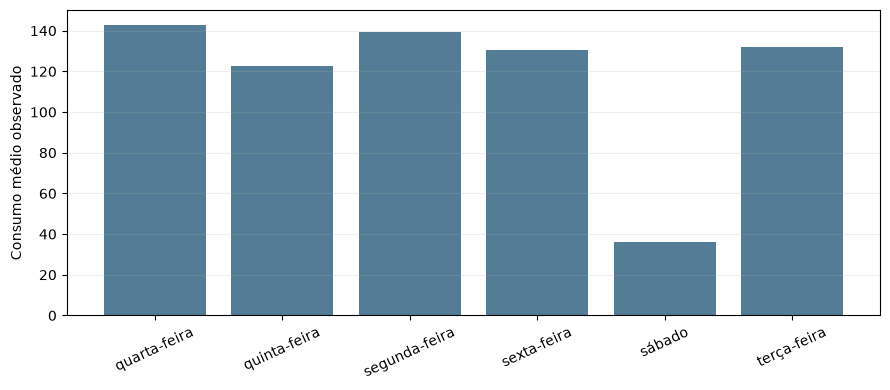

In [3]:
# Descritivos para orientar cenários; não substituem a validação temporal dos modelos
base=gold.merge(cal[["data","status_legal","evento_tipo"]],on="data",how="left",validate="one_to_one",suffixes=("","_cal"))
holidays=set(cal.loc[cal.evento_tipo.astype(str).str.casefold().str.startswith("feriado"),"data"].dt.normalize())
vac=cal.evento_tipo.astype(str).str.casefold().str.contains("ferias|recesso", regex=True)
vac_dates=set(cal.loc[vac,"data"].dt.normalize())
base["situacao_feriado"]=["véspera" if d+pd.Timedelta(days=1) in holidays else "pós-feriado" if d-pd.Timedelta(days=1) in holidays else "feriado" if d in holidays else "demais datas" for d in base.data.dt.normalize()]
base["periodo_ferias"]=["férias/recesso" if d in vac_dates else "demais datas" for d in base.data.dt.normalize()]
weekday=base.groupby("dia_semana",dropna=False).agg(n=("consumo_total","size"),media=("consumo_total","mean"),mediana=("consumo_total","median")).reset_index()
holiday_profile=base.groupby("situacao_feriado",dropna=False).agg(n=("consumo_total","size"),media=("consumo_total","mean"),mediana=("consumo_total","median")).reset_index()
vac_profile=base.groupby("periodo_ferias").agg(n=("consumo_total","size"),media=("consumo_total","mean"),mediana=("consumo_total","median")).reset_index()
display(weekday.round(2)); display(holiday_profile.round(2)); display(vac_profile.round(2))
weekday.to_csv(OUT/"perfil_dia_semana.csv",index=False,encoding="utf-8-sig")
holiday_profile.to_csv(OUT/"perfil_feriados.csv",index=False,encoding="utf-8-sig")
vac_profile.to_csv(OUT/"perfil_ferias_recesso.csv",index=False,encoding="utf-8-sig")
fig,ax=plt.subplots(figsize=(9,4)); ax.bar(weekday.dia_semana,weekday.media,color="#537D96"); ax.set_ylabel("Consumo médio observado"); ax.tick_params(axis="x",rotation=25); ax.grid(axis="y",alpha=.2); fig.tight_layout(); fig.savefig(OUT/"consumo_medio_dia_semana.png",dpi=150); plt.show()